# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$ Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [2]:
# Реализуйте это задание по постановке выше.
# Артефакт: проверенный manifest train/validation/ID/OOD/general
from collections import Counter
from PIL import Image


manifest_path = prepare_scienceqa(
    directory="data/lab9",
    smoke=FAST_DEV_RUN
)

# Загружаем сформированный JSONL
records = []

with manifest_path.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

print("=" * 60)
print("МАНИФЕСТ SCIENCEQA")
print("=" * 60)

print("Файл:", manifest_path.resolve())
print("Всего записей:", len(records))


expected_counts = {
    "train": 8 if FAST_DEV_RUN else 512,
    "validation": 4 if FAST_DEV_RUN else 64,
    "id_test": 4 if FAST_DEV_RUN else 64,
    "ood_test": 4 if FAST_DEV_RUN else 64,
    "general_test": 4 if FAST_DEV_RUN else 64
}

actual_counts = Counter(
    record["split"] for record in records
)

print("\nКоличество записей по разбиениям:")

for split, expected in expected_counts.items():

    actual = actual_counts.get(split, 0)

    print(
        f"{split:12} "
        f"Фактически: {actual:4} | "
        f"Ожидается: {expected:4}"
    )

    assert actual == expected, (
        f"Ошибка в разбиении {split}: "
        f"{actual} вместо {expected}"
    )


print("\nИсточник данных:")
print(records[0]["source_url"])

print("\nЛицензия:")
print(records[0]["license"])


print("\nПримеры записей:\n")

for record in records[:3]:

    print("ID:", record["id"])
    print("Разбиение:", record["split"])
    print("Вопрос:", record["question"])
    print("Правильный ответ:", record["answer"])
    print("Изображение:", record["image"])
    print("-" * 60)


print("\nМанифест успешно подготовлен!")

МАНИФЕСТ SCIENCEQA
Файл: /content/data/lab9/manifest.jsonl
Всего записей: 768

Количество записей по разбиениям:
train        Фактически:  512 | Ожидается:  512
validation   Фактически:   64 | Ожидается:   64
id_test      Фактически:   64 | Ожидается:   64
ood_test     Фактически:   64 | Ожидается:   64
general_test Фактически:   64 | Ожидается:   64

Источник данных:
https://huggingface.co/datasets/derek-thomas/ScienceQA/tree/f18b0a70359ebfb41f658fd564208d0355b013f4

Лицензия:
MIT (code license, lupantech/ScienceQA)

Примеры записей:

ID: scienceqa-train-9
Разбиение: train
Вопрос: Which of these organisms contains matter that was once part of the phytoplankton?
A. black rockfish
B. sea otter
Return only the letter of the correct option.
Правильный ответ: A
Изображение: /content/data/lab9/7059b2a9d6213ab2b6bc531c6adaa60811f86552fb2ac3b6acf1244b0485c5b9.png
------------------------------------------------------------
ID: scienceqa-train-11
Разбиение: train
Вопрос: Think about the magnet

### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


ВИЗУАЛЬНЫЙ АУДИТ SCIENCEQA

РАСПРЕДЕЛЕНИЕ ОТВЕТОВ

Разбиение: train
Количество: 512
Частоты: {'A': 209, 'B': 230, 'C': 72, 'D': 1}
Всего правильных ответов: 512

Разбиение: validation
Количество: 64
Частоты: {'A': 24, 'B': 32, 'C': 8, 'D': 0}
Всего правильных ответов: 64

Разбиение: ood_test
Количество: 64
Частоты: {'A': 25, 'B': 27, 'C': 9, 'D': 3}
Всего правильных ответов: 64

Разбиение: general_test
Количество: 64
Частоты: {'A': 13, 'B': 21, 'C': 17, 'D': 13}
Всего правильных ответов: 64

Разбиение: id_test
Количество: 64
Частоты: {'A': 26, 'B': 27, 'C': 11, 'D': 0}
Всего правильных ответов: 64

Профиль сохранён:
/content/artifacts/data_profile.json


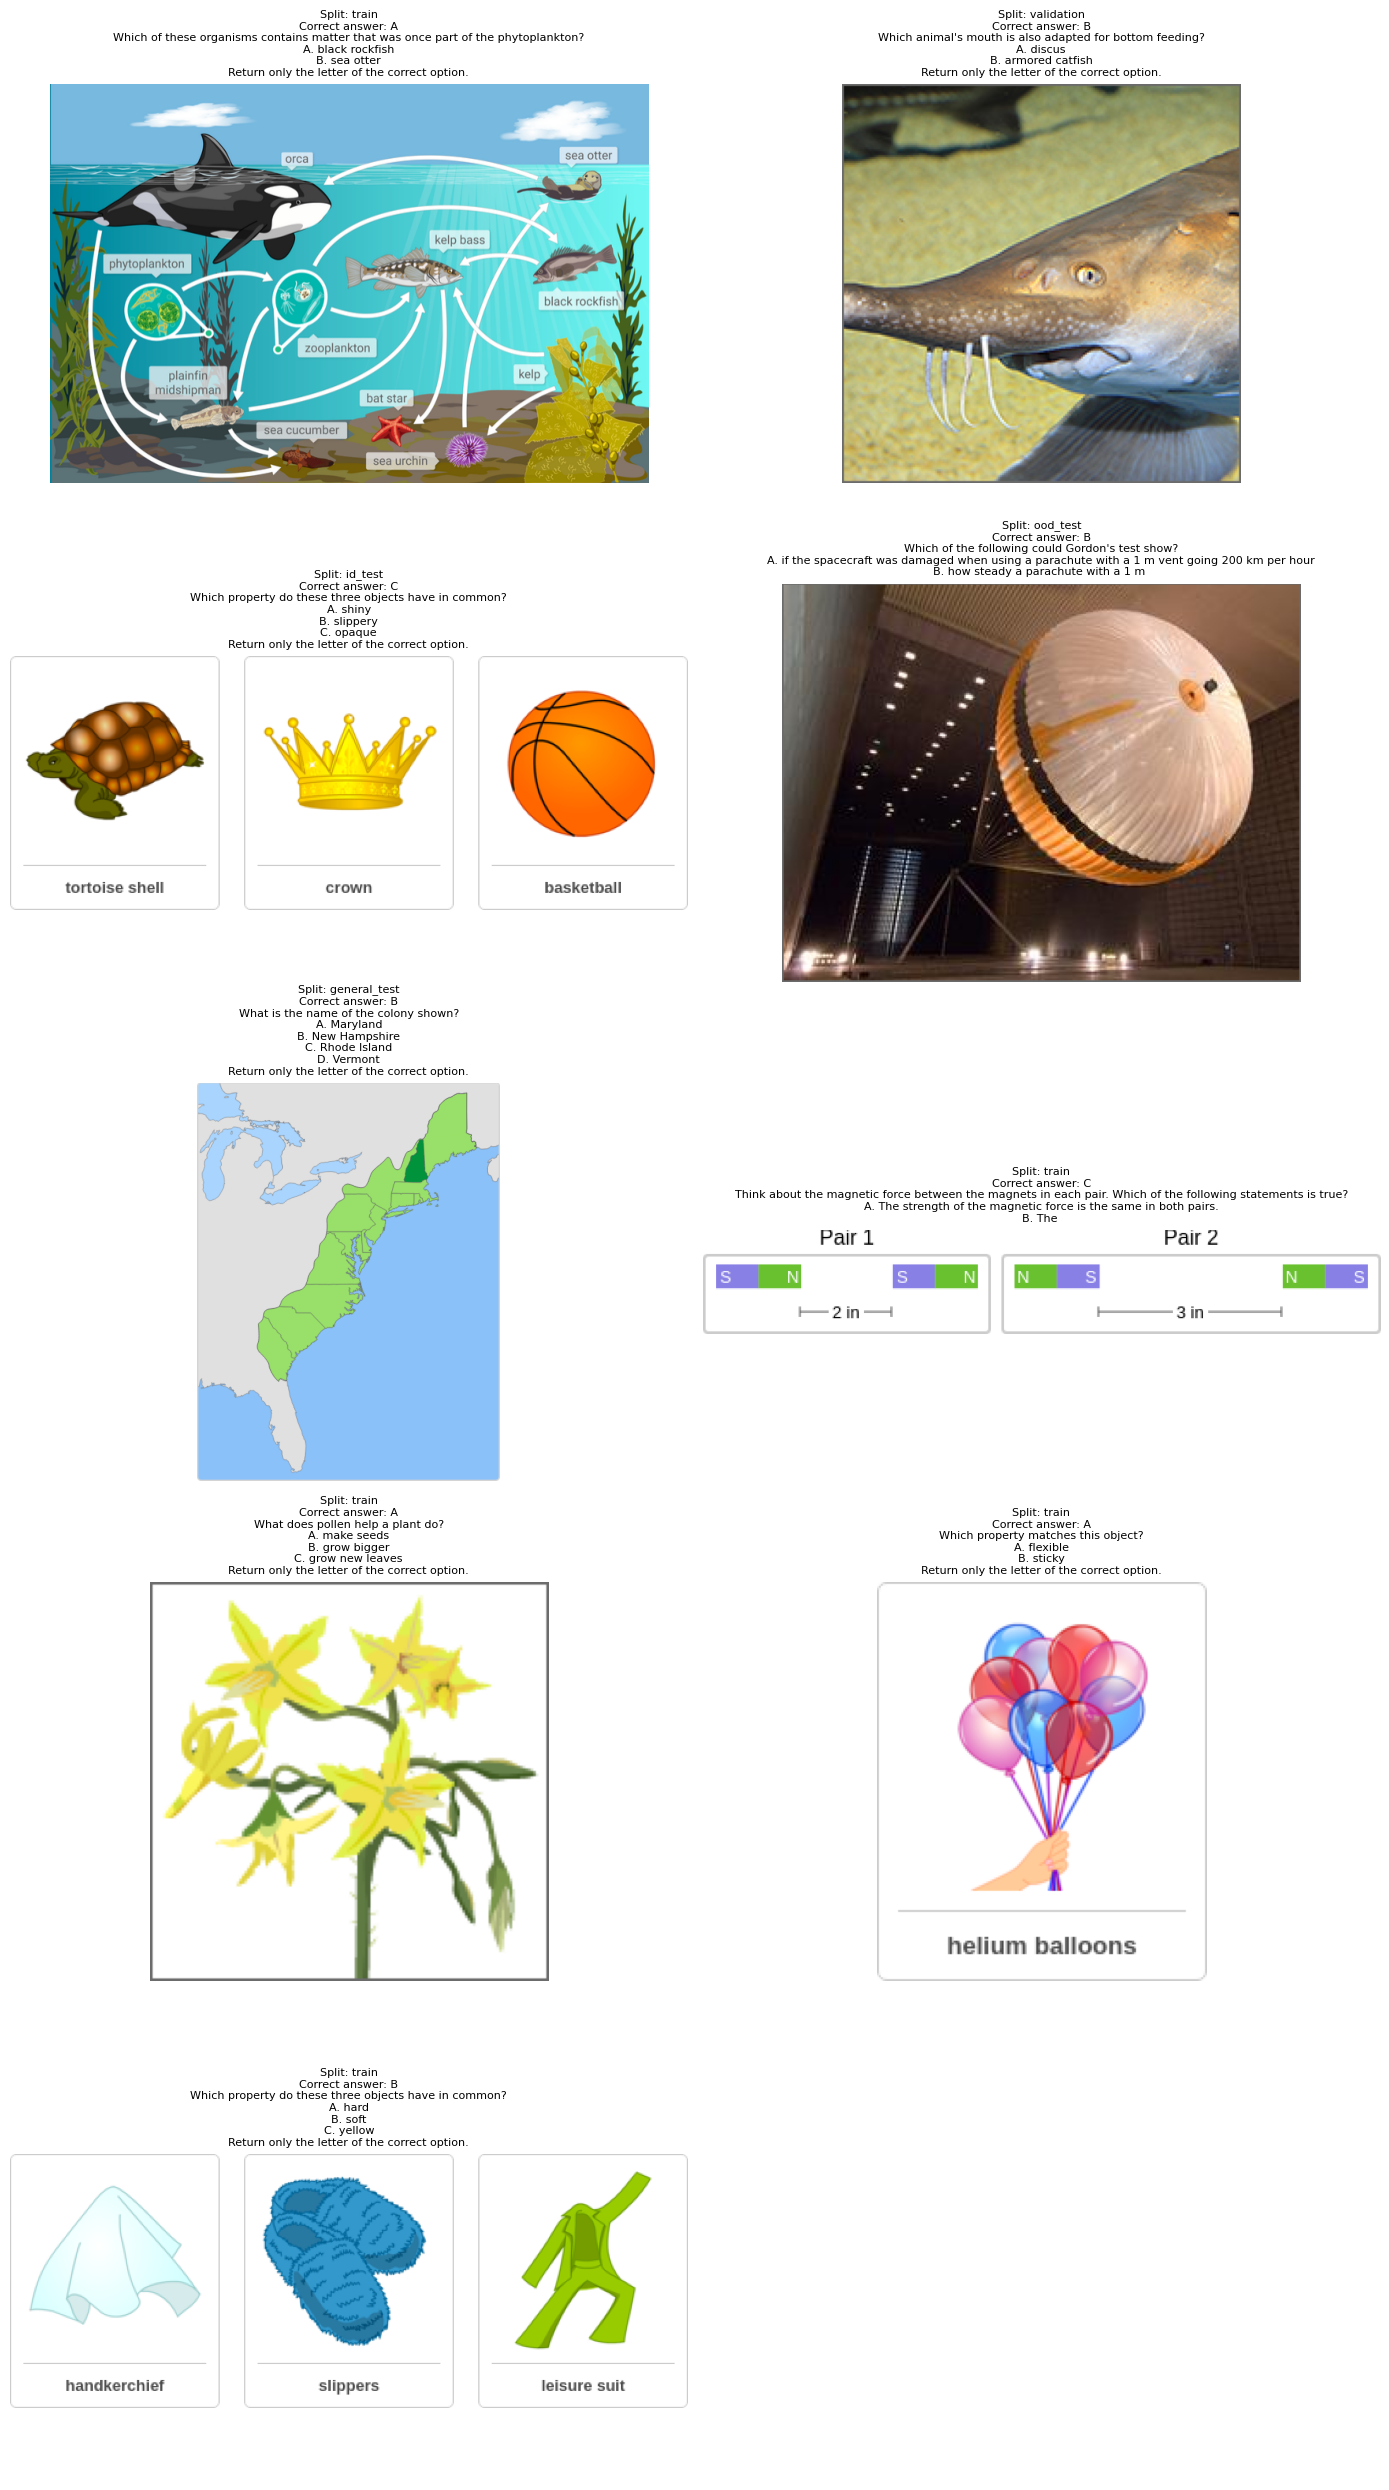


Визуальный аудит завершён.
Сетка сохранена: /content/artifacts/data_preview.png


In [3]:
# Реализуйте это задание по постановке выше.
# Артефакт: существующие файлы изображений и непустые вопросы и ответы
from collections import Counter, defaultdict
from PIL import Image
import matplotlib.pyplot as plt

print("=" * 60)
print("ВИЗУАЛЬНЫЙ АУДИТ SCIENCEQA")
print("=" * 60)

by_split = defaultdict(list)

for record in records:
    image_path = Path(record["image"])
    assert image_path.exists()
    # Проверяем, что изображение действительно декодируется.
    with Image.open(image_path) as image:
        image.verify()
    # Проверяем соответствие правильной буквы индексу.
    expected_answer = chr(
        65 + int(record["answer_index"])
    )
    assert record["answer"] == expected_answer
    assert record["question"].strip()
    by_split[record["split"]].append(record)

profile = {
    "total_examples": len(records),
    "splits": {},
    "answer_frequencies": {},
    "image_sizes": {}
}

print("\nРАСПРЕДЕЛЕНИЕ ОТВЕТОВ")

for split, items in by_split.items():
    frequencies = Counter(
        record["answer"] for record in items
    )
    # Даже если какой-то буквы нет, выводим её с нулём.
    frequencies = {
        letter: frequencies.get(letter, 0)
        for letter in "ABCD"
    }

    profile["splits"][split] = len(items)
    profile["answer_frequencies"][split] = frequencies
    print(f"\nРазбиение: {split}")
    print("Количество:", len(items))
    print("Частоты:", frequencies)
    print(
        "Всего правильных ответов:",
        sum(frequencies.values())
    )

for split, items in by_split.items():
    dimensions = []
    for record in items:
        with Image.open(record["image"]) as image:
            dimensions.append({
                "width": image.width,
                "height": image.height
            })
    profile["image_sizes"][split] = dimensions

save_json("data_profile.json", profile)
print("\nПрофиль сохранён:")
print((ARTIFACTS / "data_profile.json").resolve())


# Берём примеры из разных разбиений.
preview_records = []
for split in expected_counts:
    if by_split[split]:
        preview_records.append(by_split[split][0])

# Добавляем ещё несколько примеров train.
preview_records.extend(
    by_split["train"][1:5]
)
cols = 2
rows = (len(preview_records) + cols - 1) // cols
fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(14, 5 * rows)
)
axes = np.array(axes).reshape(-1)
for ax, record in zip(axes, preview_records):
    with Image.open(record["image"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(
        f"Split: {record['split']}\n"
        f"Correct answer: {record['answer']}\n"
        f"{record['question'][:180]}",
        fontsize=8
    )

    ax.axis("off")
for ax in axes[len(preview_records):]:
    ax.axis("off")
plt.tight_layout()
preview_path = ARTIFACTS / "data_preview.png"
plt.savefig(
    preview_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nВизуальный аудит завершён.")
print("Сетка сохранена:", preview_path.resolve())

### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [4]:
# Реализуйте это задание по постановке выше.
# Артефакт: ShareGPT JSON и dataset_info.json
DATA_DIR = Path("artifacts").resolve()
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

def convert_to_sharegpt(record):
    return {
        "conversations": [
            {
                "from": "human",
                "value": (
                    "<image>\n"
                    + record["question"]
                )
            },
            {
                "from": "gpt",
                "value": record["answer"]
            }
        ],

        "images": [
            str(
                Path(record["image"]).resolve()
            )
        ]
    }


train_data = [
    convert_to_sharegpt(record)
    for record in records
    if record["split"] == "train"
]
validation_data = [
    convert_to_sharegpt(record)
    for record in records
    if record["split"] == "validation"
]

train_path = DATA_DIR / "train.json"
validation_path = DATA_DIR / "validation.json"
train_path.write_text(
    json.dumps(
        train_data,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)
validation_path.write_text(
    json.dumps(
        validation_data,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

dataset_info = {
    "lab9_train": {
        "file_name": "train.json",
        "formatting": "sharegpt",
        "columns": {
            "messages": "conversations",
            "images": "images"
        },
        "tags": {
            "role_tag": "from",
            "content_tag": "value",
            "user_tag": "human",
            "assistant_tag": "gpt"
        }
    },
    "lab9_validation": {
        "file_name": "validation.json",
        "formatting": "sharegpt",
        "columns": {
            "messages": "conversations",
            "images": "images"
        },
        "tags": {
            "role_tag": "from",
            "content_tag": "value",
            "user_tag": "human",
            "assistant_tag": "gpt"
        }
    }
}


dataset_info_path = DATA_DIR / "dataset_info.json"
dataset_info_path.write_text(
    json.dumps(
        dataset_info,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("=" * 60)
print("ЭКСПОРТ SHAREGPT")
print("=" * 60)

print("Train:", len(train_data))
print("Validation:", len(validation_data))

print("\nФайлы:")

print(train_path.resolve())
print(validation_path.resolve())
print(dataset_info_path.resolve())


assert len(train_data) == expected_counts["train"]
assert len(validation_data) == expected_counts["validation"]


# Проверяем наличие изображений.
for item in train_data + validation_data:
    assert len(item["images"]) == 1
    assert Path(item["images"][0]).exists()
    assert len(item["conversations"]) == 2

print("\nПример экспортированной записи:\n")
print(
    json.dumps(
        train_data[0],
        ensure_ascii=False,
        indent=2
    )
)

print("\nЭкспорт успешно завершён!")

ЭКСПОРТ SHAREGPT
Train: 512
Validation: 64

Файлы:
/content/artifacts/train.json
/content/artifacts/validation.json
/content/artifacts/dataset_info.json

Пример экспортированной записи:

{
  "conversations": [
    {
      "from": "human",
      "value": "<image>\nWhich of these organisms contains matter that was once part of the phytoplankton?\nA. black rockfish\nB. sea otter\nReturn only the letter of the correct option."
    },
    {
      "from": "gpt",
      "value": "A"
    }
  ],
  "images": [
    "/content/data/lab9/7059b2a9d6213ab2b6bc531c6adaa60811f86552fb2ac3b6acf1244b0485c5b9.png"
  ]
}

Экспорт успешно завершён!


### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [5]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/sft.yaml с настоящей Qwen2.5-VL
import yaml
import torch

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

DATA_DIR = Path("data/lab9").resolve()

# Для тестового запуска используется отдельная директория,
# чтобы не смешивать smoke-checkpoint с полным обучением.
OUTPUT_DIR = (
    ARTIFACTS / (
        "lab9_adapter_smoke"
        if FAST_DEV_RUN
        else "lab9_adapter"
    )
).resolve()

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

train_steps = 2 if FAST_DEV_RUN else 100
cuda_available = torch.cuda.is_available()
if cuda_available:

    bf16_supported = torch.cuda.is_bf16_supported()

else:

    bf16_supported = False

use_bf16 = cuda_available and bf16_supported
use_fp16 = cuda_available and not bf16_supported

sft_config = {
    "model_name_or_path": MODEL_NAME,
    "trust_remote_code": True,
    "stage": "sft",
    "do_train": True,
    "do_eval": True,
    "finetuning_type": "lora",
    "quantization_method": "bitsandbytes",
    "quantization_bit": 4,
    "lora_rank": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "lora_target": "all",
    "dataset_dir": str(DATA_DIR),
    "dataset": "lab9_train",
    "eval_dataset": "lab9_validation",
    "template": "qwen2_vl",
    "cutoff_len": 2048,
    "overwrite_cache": True,
    "preprocessing_num_workers": 2,
    "dataloader_num_workers": 0,
    "output_dir": str(OUTPUT_DIR),
    "logging_steps": 1 if FAST_DEV_RUN else 5,
    "save_strategy": "steps",
    "save_steps": 1 if FAST_DEV_RUN else 20,
    "save_total_limit": 3,
    "save_only_model": False,
    "plot_loss": True,
    "overwrite_output_dir": False,
    "per_device_train_batch_size": 1,
    "gradient_accumulation_steps": 16,
    "learning_rate": 1e-4,
    "lr_scheduler_type": "cosine",
    "warmup_ratio": 0.1,
    "max_steps": train_steps,
    "num_train_epochs": 1.0,
    "per_device_eval_batch_size": 1,
    "eval_strategy": "steps",
    "eval_steps": 1 if FAST_DEV_RUN else 20,
    "load_best_model_at_end": False,
    "bf16": use_bf16,
    "fp16": use_fp16,
    "gradient_checkpointing": True,
    "report_to": "none",
    "seed": SEED
}
yaml_path = ARTIFACTS / "sft.yaml"
yaml_path.write_text(
    yaml.safe_dump(
        sft_config,
        sort_keys=False,
        allow_unicode=True
    ),
    encoding="utf-8"
)

print("\nYAML сохранён:")
print(yaml_path.resolve())
print("\nСодержимое конфигурации:\n")
print(
    yaml_path.read_text(encoding="utf-8")
)


YAML сохранён:
/content/artifacts/sft.yaml

Содержимое конфигурации:

model_name_or_path: Qwen/Qwen2.5-VL-3B-Instruct
trust_remote_code: true
stage: sft
do_train: true
do_eval: true
finetuning_type: lora
quantization_method: bitsandbytes
quantization_bit: 4
lora_rank: 8
lora_alpha: 16
lora_dropout: 0.05
lora_target: all
dataset_dir: /content/data/lab9
dataset: lab9_train
eval_dataset: lab9_validation
template: qwen2_vl
cutoff_len: 2048
overwrite_cache: true
preprocessing_num_workers: 2
dataloader_num_workers: 0
output_dir: /content/artifacts/lab9_adapter
logging_steps: 5
save_strategy: steps
save_steps: 20
save_total_limit: 3
save_only_model: false
plot_loss: true
overwrite_output_dir: false
per_device_train_batch_size: 1
gradient_accumulation_steps: 16
learning_rate: 0.0001
lr_scheduler_type: cosine
warmup_ratio: 0.1
max_steps: 100
num_train_epochs: 1.0
per_device_eval_batch_size: 1
eval_strategy: steps
eval_steps: 20
load_best_model_at_end: false
bf16: true
fp16: false
gradient_chec

### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [6]:
# Реализуйте это задание по постановке выше.
# Артефакт: выбранный checkpoint того же прогона
import hashlib
import re
import yaml

yaml_path = ARTIFACTS / "sft.yaml"
config = yaml.safe_load(
    yaml_path.read_text(encoding="utf-8")
)
output_dir = Path(
    config["output_dir"]
)
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

def calculate_config_hash(config):
    stable_config = {
        key: value
        for key, value in config.items()
        if key != "resume_from_checkpoint"
    }
    config_string = json.dumps(
        stable_config,
        sort_keys=True,
        ensure_ascii=False
    )
    return hashlib.sha256(
        config_string.encode("utf-8")
    ).hexdigest()


current_hash = calculate_config_hash(config)
fingerprint_path = (
    output_dir / "run_config_sha256.txt"
)

checkpoints = []
for checkpoint_dir in output_dir.glob("checkpoint-*"):
    match = re.fullmatch(
        r"checkpoint-(\d+)",
        checkpoint_dir.name
    )
    if not match:
        continue
    step_from_name = int(match.group(1))
    trainer_state_path = (
        checkpoint_dir / "trainer_state.json"
    )
    if not trainer_state_path.exists():
        continue
    with trainer_state_path.open(
        "r",
        encoding="utf-8"
    ) as f:
        trainer_state = json.load(f)
    actual_step = int(
        trainer_state["global_step"]
    )

    if step_from_name != actual_step:
        continue
    checkpoints.append({
        "step": actual_step,
        "path": checkpoint_dir
    })

checkpoints.sort(
    key=lambda item: item["step"]
)
last_checkpoint = (
    checkpoints[-1]
    if checkpoints
    else None
)
if last_checkpoint is not None:
    if not fingerprint_path.exists():
        raise RuntimeError(
            "Найден checkpoint, но отсутствует fingerprint "
            "предыдущей конфигурации. Безопасное возобновление "
            "невозможно."
        )
    saved_hash = fingerprint_path.read_text(
        encoding="utf-8"
    ).strip()
    if saved_hash != current_hash:
        raise RuntimeError(
            "Конфигурация отличается от предыдущего запуска! "
            "Возобновление запрещено."
        )

    config["resume_from_checkpoint"] = str(
        last_checkpoint["path"].resolve()
    )
    mode = "resume"

else:
    config.pop(
        "resume_from_checkpoint",
        None
    )
    mode = "new"

yaml_path.write_text(
    yaml.safe_dump(
        config,
        sort_keys=False,
        allow_unicode=True
    ),
    encoding="utf-8"
)

protocol = {

    "mode": mode,
    "resume_from_checkpoint": (
        str(last_checkpoint["path"].resolve())
        if last_checkpoint
        else None
    ),
    "checkpoint_global_step": (
        last_checkpoint["step"]
        if last_checkpoint
        else None
    ),
    "config_sha256": current_hash,
    "total_checkpoints_found": len(checkpoints),
    "explanation": (
        "Resume восстанавливает веса модели и сохранённое "
        "состояние Trainer, включая состояние оптимизатора "
        "и scheduler. Загрузка только adapter weights "
        "не восстанавливает состояние оптимизатора."
    )
}

save_json(
    "resume_protocol.json",
    protocol
)


print("=" * 60)
print("ПРОВЕРКА CHECKPOINT")
print("=" * 60)

print("Количество найденных checkpoint:", len(checkpoints))

for checkpoint in checkpoints:

    print(
        f"Step {checkpoint['step']:4} | "
        f"{checkpoint['path']}"
    )


print("\nРежим запуска:", mode)

print(
    "Выбранный checkpoint:",
    protocol["resume_from_checkpoint"]
)

print(
    "\nFingerprint конфигурации:",
    current_hash
)

print("\nПротокол сохранён:")
print((ARTIFACTS / "resume_protocol.json").resolve())

print("\nОбновлённый YAML:")
print(yaml_path.resolve())

ПРОВЕРКА CHECKPOINT
Количество найденных checkpoint: 0

Режим запуска: new
Выбранный checkpoint: None

Fingerprint конфигурации: a30fa043b7b14b58aeabc7092a9561cac3dc869d63f1952287e330fe89e8bb74

Протокол сохранён:
/content/artifacts/resume_protocol.json

Обновлённый YAML:
/content/artifacts/sft.yaml


### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [7]:
%pip install llamafactory

In [8]:
# Реализуйте это задание по постановке выше.
# Артефакт: обученный lab9_adapter и train.log
import subprocess
import sys
import shutil
import gc
import importlib.metadata
import platform
import torch
import yaml

yaml_path = ARTIFACTS / "sft.yaml"
config = yaml.safe_load(
    yaml_path.read_text(encoding="utf-8")
)
output_dir = Path(
    config["output_dir"]
)
output_dir.mkdir(
    parents=True,
    exist_ok=True
)
expected_steps = int(
    config["max_steps"]
)

cli_path = shutil.which(
    "llamafactory-cli"
)
if cli_path is None:
    raise FileNotFoundError(
        "Команда llamafactory-cli не найдена. "
        "Сначала установите LLaMA-Factory."
    )

packages = [
    "torch",
    "transformers",
    "datasets",
    "peft",
    "bitsandbytes",
    "llamafactory",
    "accelerate",
    "qwen-vl-utils"
]

version_info = {
    "python": sys.version,
    "platform": platform.platform(),
    "model": config["model_name_or_path"],
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0),
    "packages": {},
    "training_steps": expected_steps,
    "fast_dev_run": FAST_DEV_RUN,
    "llamafactory_command": cli_path
}


for package in packages:
    try:
        version_info["packages"][package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        version_info["packages"][package] = None

save_json(
    "version.json",
    version_info
)

current_hash = calculate_config_hash(config)
fingerprint_path = (
    output_dir / "run_config_sha256.txt"
)
fingerprint_path.write_text(
    current_hash,
    encoding="utf-8"
)

cmd = [
    cli_path,
    "train",
    str(yaml_path.resolve())
]

log_path = ARTIFACTS / "train.log"

print("\n" + "=" * 60)
print("ЗАПУСК LLaMA-FACTORY")
print("=" * 60)

print("Команда:")
print(" ".join(cmd))

print("\nПолный лог будет сохранён в:")
print(log_path.resolve())

print("\nНачинаем обучение...\n")

with log_path.open(
    "w",
    encoding="utf-8"
) as log_file:

    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        bufsize=1
    )
    for line in process.stdout:
        print(
            line,
            end=""
        )
        log_file.write(line)
        log_file.flush()
    return_code = process.wait()

print("\n" + "=" * 60)
print("Код завершения:", return_code)
if return_code != 0:
    raise RuntimeError(
        "Обучение завершилось с ошибкой. "
        f"Проверьте лог: {log_path.resolve()}"
    )

adapter_files = (
    list(output_dir.rglob("adapter_model.safetensors"))
    +
    list(output_dir.rglob("adapter_model.bin"))
)

trainer_states = list(
    output_dir.rglob("trainer_state.json")
)


if not adapter_files:

    raise FileNotFoundError(
        "Обучение завершилось, но файлы адаптера не найдены."
    )


if not trainer_states:

    raise FileNotFoundError(
        "Не обнаружены файлы trainer_state.json."
    )

final_states = []
for state_path in trainer_states:
    with state_path.open(
        "r",
        encoding="utf-8"
    ) as f:
        state = json.load(f)
    final_states.append({
        "path": str(state_path),
        "global_step": state.get("global_step")
    })

max_global_step = max(
    int(state["global_step"])
    for state in final_states
)

print("\nФактически выполнено шагов:", max_global_step)
print("Требовалось шагов:", expected_steps)

if max_global_step < expected_steps:
    raise RuntimeError(
        f"Обучение выполнило только {max_global_step} "
        f"из {expected_steps} шагов."
    )
print("\nПолное обучение успешно завершено!")

print("\nЛог:", log_path.resolve())


ЗАПУСК LLaMA-FACTORY
Команда:
/usr/local/bin/llamafactory-cli train /content/artifacts/sft.yaml

Полный лог будет сохранён в:
/content/artifacts/train.log

Начинаем обучение...

/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg

### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [12]:
# Реализуйте это задание по постановке выше.
# Артефакт: процессор, base и детерминированный predict
import gc
import torch

from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
    BitsAndBytesConfig
)
from peft import PeftModel
from qwen_vl_utils import process_vision_info

COMPUTE_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)
processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)
print("Процессор загружен:", type(processor).__name__)

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE
)

def load_base_model():
    print("\nЗагрузка базовой модели...")
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_NAME,
        quantization_config=quantization_config,
        device_map="auto",
        torch_dtype=COMPUTE_DTYPE,
        trust_remote_code=True
    )
    model.eval()
    print("Базовая модель успешно загружена.")
    return model

def find_adapter_directory(output_dir):
    output_dir = Path(output_dir)
    # В первую очередь проверяем итоговую директорию.
    if (output_dir / "adapter_config.json").exists():
        return output_dir
    # Если адаптер находится только в checkpoint,
    # выбираем последний по числу шагов.
    candidates = []
    for path in output_dir.glob("checkpoint-*"):
        match = re.fullmatch(
            r"checkpoint-(\d+)",
            path.name
        )
        if match and (path / "adapter_config.json").exists():
            candidates.append(
                (int(match.group(1)), path)
            )
    if not candidates:
        raise FileNotFoundError(
            f"Адаптер не найден в {output_dir}"
        )

    candidates.sort(
        key=lambda item: item[0]
    )
    return candidates[-1][1]

def load_sft_model(output_dir):

    print("\nЗагрузка дообученной модели...")
    adapter_dir = find_adapter_directory(
        output_dir
    )
    print("Используется адаптер:")
    print(adapter_dir.resolve())
    base_model = load_base_model()
    model = PeftModel.from_pretrained(
        base_model,
        str(adapter_dir.resolve()),
        is_trainable=False
    )
    model.eval()
    print("LoRA-адаптер успешно подключён.")

    return model

def predict(model,image_path,question,max_new_tokens=16):

    image_path = Path(image_path).resolve()
    if not image_path.exists():
        raise FileNotFoundError(image_path)
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": str(image_path)
                },
                {
                    "type": "text",
                    "text": question
                }
            ]
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(
        messages
    )
    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )
    inputs = inputs.to(model.device)

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            num_beams=1,
            use_cache=True
        )

    prompt_length = inputs["input_ids"].shape[1]
    generated_continuation = generated_ids[
        :, prompt_length:
    ]

    output_text = processor.batch_decode(
        generated_continuation,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )
    return output_text[0].strip()


print("\n" + "=" * 60)
print("ИНФЕРЕНС ПОДГОТОВЛЕН")
print("=" * 60)
print("Модель:", MODEL_NAME)
print("Вычислительный тип:", COMPUTE_DTYPE)
print("Функция predict() готова к использованию.")

Процессор загружен: Qwen2_5_VLProcessor

ИНФЕРЕНС ПОДГОТОВЛЕН
Модель: Qwen/Qwen2.5-VL-3B-Instruct
Вычислительный тип: torch.bfloat16
Функция predict() готова к использованию.


### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [25]:
# Реализуйте это задание по постановке выше.
# Артефакт: ответы base на ID/OOD/general test
test_records = [
    record
    for record in records
    if record["split"] in (
        "id_test",
        "ood_test",
        "general_test"
    )
]

print("=" * 60)
print("ТЕСТИРОВАНИЕ БАЗОВОЙ МОДЕЛИ")
print("=" * 60)
print("Всего тестовых примеров:", len(test_records))

for split in ("id_test", "ood_test", "general_test"):
    count = sum(
        record["split"] == split
        for record in test_records
    )
    print(f"{split}: {count}")

base_model = load_base_model()

base_predictions_path = (
    ARTIFACTS / "base_predictions.jsonl"
)
base_predictions = []
try:

    with base_predictions_path.open(
        "w",
        encoding="utf-8"
    ) as f:
        for i, record in enumerate(
            test_records,
            start=1
        ):
            raw_prediction = predict(
                model=base_model,
                image_path=record["image"],
                question=record["question"]
            )
            result = {
                "id": record["id"],
                "split": record["split"],
                "gold": record["answer"],
                "prediction": raw_prediction,
                "image": record["image"]
            }
            base_predictions.append(result)

            f.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )
            f.flush()
            print(
                f"[{i}/{len(test_records)}] "
                f"{record['split']} | "
                f"Правильный ответ: {record['answer']} | "
                f"Предсказание Base: {raw_prediction!r}"
            )
finally:
    # Освобождаем видеопамять.
    del base_model
    gc.collect()
    torch.cuda.empty_cache()

assert len(base_predictions) == len(test_records)
assert len({
    item["id"]
    for item in base_predictions
}) == len(test_records)


print("\n" + "=" * 60)
print("БАЗОВОЕ ТЕСТИРОВАНИЕ ЗАВЕРШЕНО")
print("=" * 60)
print("Получено предсказаний:", len(base_predictions))
print("Результаты сохранены:")
print(base_predictions_path.resolve())

for split in ("id_test", "ood_test", "general_test"):
    count = sum(
        item["split"] == split
        for item in base_predictions
    )
    print(f"{split}: {count} предсказаний")

print("\nПример сохранённого результата:")
print(
    json.dumps(
        base_predictions[0],
        ensure_ascii=False,
        indent=2
    )
)

ТЕСТИРОВАНИЕ БАЗОВОЙ МОДЕЛИ
Всего тестовых примеров: 192
id_test: 64
ood_test: 64
general_test: 64

Загрузка базовой модели...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Базовая модель успешно загружена.


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[1/192] ood_test | Правильный ответ: B | Предсказание Base: 'B'
[2/192] general_test | Правильный ответ: B | Предсказание Base: 'B'
[3/192] ood_test | Правильный ответ: B | Предсказание Base: 'E'
[4/192] id_test | Правильный ответ: C | Предсказание Base: 'C'
[5/192] ood_test | Правильный ответ: C | Предсказание Base: 'A'
[6/192] general_test | Правильный ответ: D | Предсказание Base: 'D'
[7/192] id_test | Правильный ответ: B | Предсказание Base: 'B'
[8/192] id_test | Правильный ответ: A | Предсказание Base: 'A'
[9/192] general_test | Правильный ответ: C | Предсказание Base: 'C'
[10/192] general_test | Правильный ответ: A | Предсказание Base: 'A'
[11/192] general_test | Правильный ответ: D | Предсказание Base: 'D'
[12/192] general_test | Правильный ответ: D | Предсказание Base: 'D'
[13/192] general_test | Правильный ответ: D | Предсказание Base: 'D'
[14/192] ood_test | Правильный ответ: B | Предсказание Base: 'A'
[15/192] id_test | Правильный ответ: B | Предсказание Base: 'B'
[16/192] i

### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [26]:
# Реализуйте это задание по постановке выше.
# Артефакт: парные ответы адаптера в artifacts/predictions.jsonl

base_predictions_path = (
    ARTIFACTS / "base_predictions.jsonl"
)
if not base_predictions_path.exists():
    raise FileNotFoundError(
        "Сначала выполните ячейку № 23."
    )

base_predictions = []
with base_predictions_path.open(
    "r",
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            base_predictions.append(
                json.loads(line)
            )

# Формируем словарь для быстрого поиска по ID.

base_by_id = {
    item["id"]: item
    for item in base_predictions
}
record_by_id = {
    item["id"]: item
    for item in records
}
assert len(base_by_id) == len(base_predictions)

test_ids = {
    record["id"]
    for record in records
    if record["split"] in (
        "id_test",
        "ood_test",
        "general_test"
    )
}
assert set(base_by_id.keys()) == test_ids, (
    "Набор ID в base_predictions не совпадает с тестовым набором."
)

sft_config = yaml.safe_load(
    (ARTIFACTS / "sft.yaml").read_text(
        encoding="utf-8"
    )
)
adapter_dir = Path(
    sft_config["output_dir"]
)
sft_model = load_sft_model(
    adapter_dir
)


paired_predictions_path = (
    ARTIFACTS / "predictions.jsonl"
)
paired_predictions = []

try:
    with paired_predictions_path.open(
        "w",
        encoding="utf-8"
    ) as f:
        for i, base_result in enumerate(base_predictions,start=1):
            record = record_by_id[base_result["id"]]
            sft_prediction = predict(
                model=sft_model,
                image_path=record["image"],
                question=record["question"]
            )
            result = {
                "id": record["id"],
                "split": record["split"],
                "gold": record["answer"],
                "base_prediction": base_result["prediction"],
                "sft_prediction": sft_prediction
            }
            paired_predictions.append(result)

            f.write(
                json.dumps(
                    result,
                    ensure_ascii=False
                ) + "\n"
            )
            f.flush()
            print(
                f"[{i}/{len(base_predictions)}] "
                f"Split: {record['split']} | "
                f"Gold: {record['answer']} | "
                f"Base: {base_result['prediction']!r} | "
                f"SFT: {sft_prediction!r}"
            )


finally:
    del sft_model
    gc.collect()
    torch.cuda.empty_cache()

assert len(paired_predictions) == len(base_predictions)
assert len({
    item["id"]
    for item in paired_predictions
}) == len(paired_predictions)

for item in paired_predictions:
    assert item["base_prediction"] is not None
    assert item["sft_prediction"] is not None


print("\n" + "=" * 60)
print("ПАРНОЕ ТЕСТИРОВАНИЕ ЗАВЕРШЕНО")
print("=" * 60)
print("Всего пар:", len(paired_predictions))
print(
    "Файл:",
    paired_predictions_path.resolve()
)

print("\nПример парного результата:")
print(
    json.dumps(
        paired_predictions[0],
        ensure_ascii=False,
        indent=2
    )
)


Загрузка дообученной модели...
Используется адаптер:
/content/artifacts/lab9_adapter

Загрузка базовой модели...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Базовая модель успешно загружена.
LoRA-адаптер успешно подключён.
[1/192] Split: ood_test | Gold: B | Base: 'B' | SFT: 'C'
[2/192] Split: general_test | Gold: B | Base: 'B' | SFT: 'B'
[3/192] Split: ood_test | Gold: B | Base: 'E' | SFT: 'B'
[4/192] Split: id_test | Gold: C | Base: 'C' | SFT: 'C'
[5/192] Split: ood_test | Gold: C | Base: 'A' | SFT: 'A'
[6/192] Split: general_test | Gold: D | Base: 'D' | SFT: 'D'
[7/192] Split: id_test | Gold: B | Base: 'B' | SFT: 'A'
[8/192] Split: id_test | Gold: A | Base: 'A' | SFT: 'A'
[9/192] Split: general_test | Gold: C | Base: 'C' | SFT: 'C'
[10/192] Split: general_test | Gold: A | Base: 'A' | SFT: 'A'
[11/192] Split: general_test | Gold: D | Base: 'D' | SFT: 'D'
[12/192] Split: general_test | Gold: D | Base: 'D' | SFT: 'D'
[13/192] Split: general_test | Gold: D | Base: 'D' | SFT: 'D'
[14/192] Split: ood_test | Gold: B | Base: 'A' | SFT: 'A'
[15/192] Split: id_test | Gold: B | Base: 'B' | SFT: 'B'
[16/192] Split: id_test | Gold: B | Base: 'C' | S

### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [27]:
# Реализуйте это задание по постановке выше.
# Артефакт: artifacts/evaluation.json с n и exact match

predictions_path = (
    ARTIFACTS / "predictions.jsonl"
)
if not predictions_path.exists():
    raise FileNotFoundError(
        "Сначала выполните ячейку № 25."
    )
paired_predictions = []
with predictions_path.open(
    "r",
    encoding="utf-8"
) as f:
    for line in f:
        if line.strip():
            paired_predictions.append(
                json.loads(line)
            )

def strict_exact_match(prediction, gold):

    prediction = str(
        prediction
    ).strip().upper()

    gold = str(
        gold
    ).strip().upper()

    return prediction == gold


def is_valid_answer_format(prediction):

    prediction = str(
        prediction
    ).strip().upper()

    return prediction in list("ABCDE")

evaluation = {
    "metric": "Strict Exact Match",
    "normalization": "strip + uppercase",
    "splits": {}
}

for split in (
    "id_test",
    "ood_test",
    "general_test"
):

    subset = [
        item
        for item in paired_predictions
        if item["split"] == split
    ]
    n = len(subset)
    if n == 0:
        raise RuntimeError(
            f"Разбиение {split} пустое."
        )
    base_correct = sum(
        strict_exact_match(
            item["base_prediction"],
            item["gold"]
        )
        for item in subset
    )

    sft_correct = sum(
        strict_exact_match(
            item["sft_prediction"],
            item["gold"]
        )
        for item in subset
    )

    base_accuracy = base_correct / n
    sft_accuracy = sft_correct / n

    base_invalid = sum(
        not is_valid_answer_format(
            item["base_prediction"]
        )
        for item in subset
    )

    sft_invalid = sum(
        not is_valid_answer_format(
            item["sft_prediction"]
        )
        for item in subset
    )

    delta = sft_accuracy - base_accuracy
    evaluation["splits"][split] = {
        "n": n,
        "base_correct": base_correct,
        "sft_correct": sft_correct,
        "base_exact_match": base_accuracy,
        "sft_exact_match": sft_accuracy,
        "delta": delta,
        "base_invalid_format": base_invalid,
        "sft_invalid_format": sft_invalid
    }

save_json(
    "evaluation.json",
    evaluation
)

print("=" * 60)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛИ")
print("=" * 60)

for split, metrics in evaluation["splits"].items():

    print(f"\nРАЗБИЕНИЕ: {split}")
    print("-" * 50)
    print("Количество примеров:", metrics["n"])
    print(
        "Base:",
        f"{metrics['base_exact_match']:.4f}",
        f"({metrics['base_correct']}/{metrics['n']})"
    )
    print(
        "SFT:",
        f"{metrics['sft_exact_match']:.4f}",
        f"({metrics['sft_correct']}/{metrics['n']})"
    )
    print(
        "Изменение:",
        f"{metrics['delta']:+.4f}"
    )
    print(
        "Некорректный формат Base:",
        metrics["base_invalid_format"]
    )
    print(
        "Некорректный формат SFT:",
        metrics["sft_invalid_format"]
    )


print("\n" + "=" * 60)
print("ПРИМЕРЫ ИЗМЕНЕНИЯ ПРЕДСКАЗАНИЙ")
print("=" * 60)
changed = [
    item
    for item in paired_predictions
    if item["base_prediction"].strip()
    != item["sft_prediction"].strip()
]

print("Количество изменившихся ответов:", len(changed))


for item in changed[:10]:
    print("\nID:", item["id"])
    print("Split:", item["split"])
    print("Gold:", item["gold"])
    print("Base:", item["base_prediction"])
    print("SFT:", item["sft_prediction"])

print("\nФайл с метриками:")
print(
    (ARTIFACTS / "evaluation.json").resolve()
)

РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛИ

РАЗБИЕНИЕ: id_test
--------------------------------------------------
Количество примеров: 64
Base: 0.7969 (51/64)
SFT: 0.8594 (55/64)
Изменение: +0.0625
Некорректный формат Base: 8
Некорректный формат SFT: 0

РАЗБИЕНИЕ: ood_test
--------------------------------------------------
Количество примеров: 64
Base: 0.5469 (35/64)
SFT: 0.7031 (45/64)
Изменение: +0.1562
Некорректный формат Base: 2
Некорректный формат SFT: 0

РАЗБИЕНИЕ: general_test
--------------------------------------------------
Количество примеров: 64
Base: 0.8906 (57/64)
SFT: 0.8906 (57/64)
Изменение: +0.0000
Некорректный формат Base: 0
Некорректный формат SFT: 0

ПРИМЕРЫ ИЗМЕНЕНИЯ ПРЕДСКАЗАНИЙ
Количество изменившихся ответов: 30

ID: scienceqa-test-1
Split: ood_test
Gold: B
Base: B
SFT: C

ID: scienceqa-test-9
Split: ood_test
Gold: B
Base: E
SFT: B

ID: scienceqa-test-17
Split: id_test
Gold: B
Base: B
SFT: A

ID: scienceqa-test-36
Split: id_test
Gold: B
Base: C
SFT: B

ID: scienceqa-test-49
Spli

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.